In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42

In [ ]:
!pip install -q kagglehub
import kagglehub, glob

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
csv_file = glob.glob(f"{path}/*.csv")[0]
df = pd.read_csv(csv_file)

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1230 entries, 0 to 1229
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1230 non-null   int64
 1   Attrition                 1230 non-null   int64
 2   BusinessTravel            1230 non-null   int64
 3   DailyRate                 1230 non-null   int64
 4   Department                1230 non-null   int64
 5   DistanceFromHome          1230 non-null   int64
 6   Education                 1230 non-null   int64
 7   EducationField            1230 non-null   int64
 8   EnvironmentSatisfaction   1230 non-null   int64
 9   Gender                    1230 non-null   int64
 10  HourlyRate                1230 non-null   int64
 11  JobInvolvement            1230 non-null   int64
 12  JobLevel                  1230 non-null   int64
 13  JobRole                   1230 non-null   int64
 14  JobSatisfaction           1230 non-null 

In [ ]:
df.head(10)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,2,1102,2,1,2,1,2,0,...,3,1,0,8,0,1,6,4,0,5
1,49,0,1,279,1,8,1,1,3,1,...,4,4,1,10,3,3,10,7,1,7
2,37,1,2,1373,1,2,2,4,4,1,...,3,2,0,7,3,3,0,0,0,0
3,33,0,1,1392,1,3,4,1,4,0,...,3,3,0,8,3,3,8,7,3,0
4,27,0,2,591,1,2,1,3,1,1,...,3,4,1,6,3,3,2,2,2,2
5,32,0,1,1005,1,2,2,1,4,1,...,3,3,0,8,2,2,7,7,3,6
6,59,0,2,1324,1,3,3,3,3,0,...,4,1,3,12,3,2,1,0,0,0
7,30,0,2,1358,1,24,1,1,4,1,...,4,2,1,1,2,3,1,0,0,0
8,38,0,1,216,1,23,3,1,4,1,...,4,2,0,10,2,3,9,7,1,8
9,36,0,2,1299,1,27,3,3,3,1,...,3,2,2,17,3,2,7,7,7,7


In [ ]:
print("no.nulls",df.isnull().sum().sum())

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
id_cols = [c for c in ["EmployeeNumber"] if c in df.columns]
df = df.drop(columns=constant_cols + id_cols)

print("Dropped:", constant_cols + id_cols)
print(df["Attrition"].value_counts(normalize=True).round(3))

0 missing values
Dropped: ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeNumber']
Attrition
No     0.839
Yes    0.161
Name: proportion, dtype: float64


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns
continuous_cols = [c for c in numeric_cols if df[c].nunique() > 15]

before = len(df)
mask = pd.Series(True, index=df.index)
outliers_per_col = {}

for col in continuous_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_out = (df[col] < low) | (df[col] > high)
    outliers_per_col[col] = int(is_out.sum())
    mask &= ~is_out

df = df[mask].reset_index(drop=True)

print("Outliers flagged per column:", outliers_per_col)
print(f"Rows: {before} -> {len(df)} (removed {before - len(df)}, {(before - len(df)) / before:.1%})")

Outliers flagged per column: {'Age': 0, 'DailyRate': 0, 'DistanceFromHome': 0, 'HourlyRate': 0, 'MonthlyIncome': 114, 'MonthlyRate': 0, 'TotalWorkingYears': 63, 'YearsAtCompany': 104, 'YearsInCurrentRole': 21, 'YearsSinceLastPromotion': 107, 'YearsWithCurrManager': 14}
Rows: 1470 -> 1230 (removed 240, 16.3%)


In [ ]:
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
mappings = {}

for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    mappings[col] = {cls: int(i) for i, cls in enumerate(le.classes_)}

for col, m in mappings.items():
    print(col, m)

df.head()

Attrition {'No': 0, 'Yes': 1}
BusinessTravel {'Non-Travel': 0, 'Travel_Frequently': 1, 'Travel_Rarely': 2}
Department {'Human Resources': 0, 'Research & Development': 1, 'Sales': 2}
EducationField {'Human Resources': 0, 'Life Sciences': 1, 'Marketing': 2, 'Medical': 3, 'Other': 4, 'Technical Degree': 5}
Gender {'Female': 0, 'Male': 1}
JobRole {'Healthcare Representative': 0, 'Human Resources': 1, 'Laboratory Technician': 2, 'Manager': 3, 'Manufacturing Director': 4, 'Research Director': 5, 'Research Scientist': 6, 'Sales Executive': 7, 'Sales Representative': 8}
MaritalStatus {'Divorced': 0, 'Married': 1, 'Single': 2}
OverTime {'No': 0, 'Yes': 1}


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,2,1102,2,1,2,1,2,0,...,3,1,0,8,0,1,6,4,0,5
1,49,0,1,279,1,8,1,1,3,1,...,4,4,1,10,3,3,10,7,1,7
2,37,1,2,1373,1,2,2,4,4,1,...,3,2,0,7,3,3,0,0,0,0
3,33,0,1,1392,1,3,4,1,4,0,...,3,3,0,8,3,3,8,7,3,0
4,27,0,2,591,1,2,1,3,1,1,...,3,4,1,6,3,3,2,2,2,2


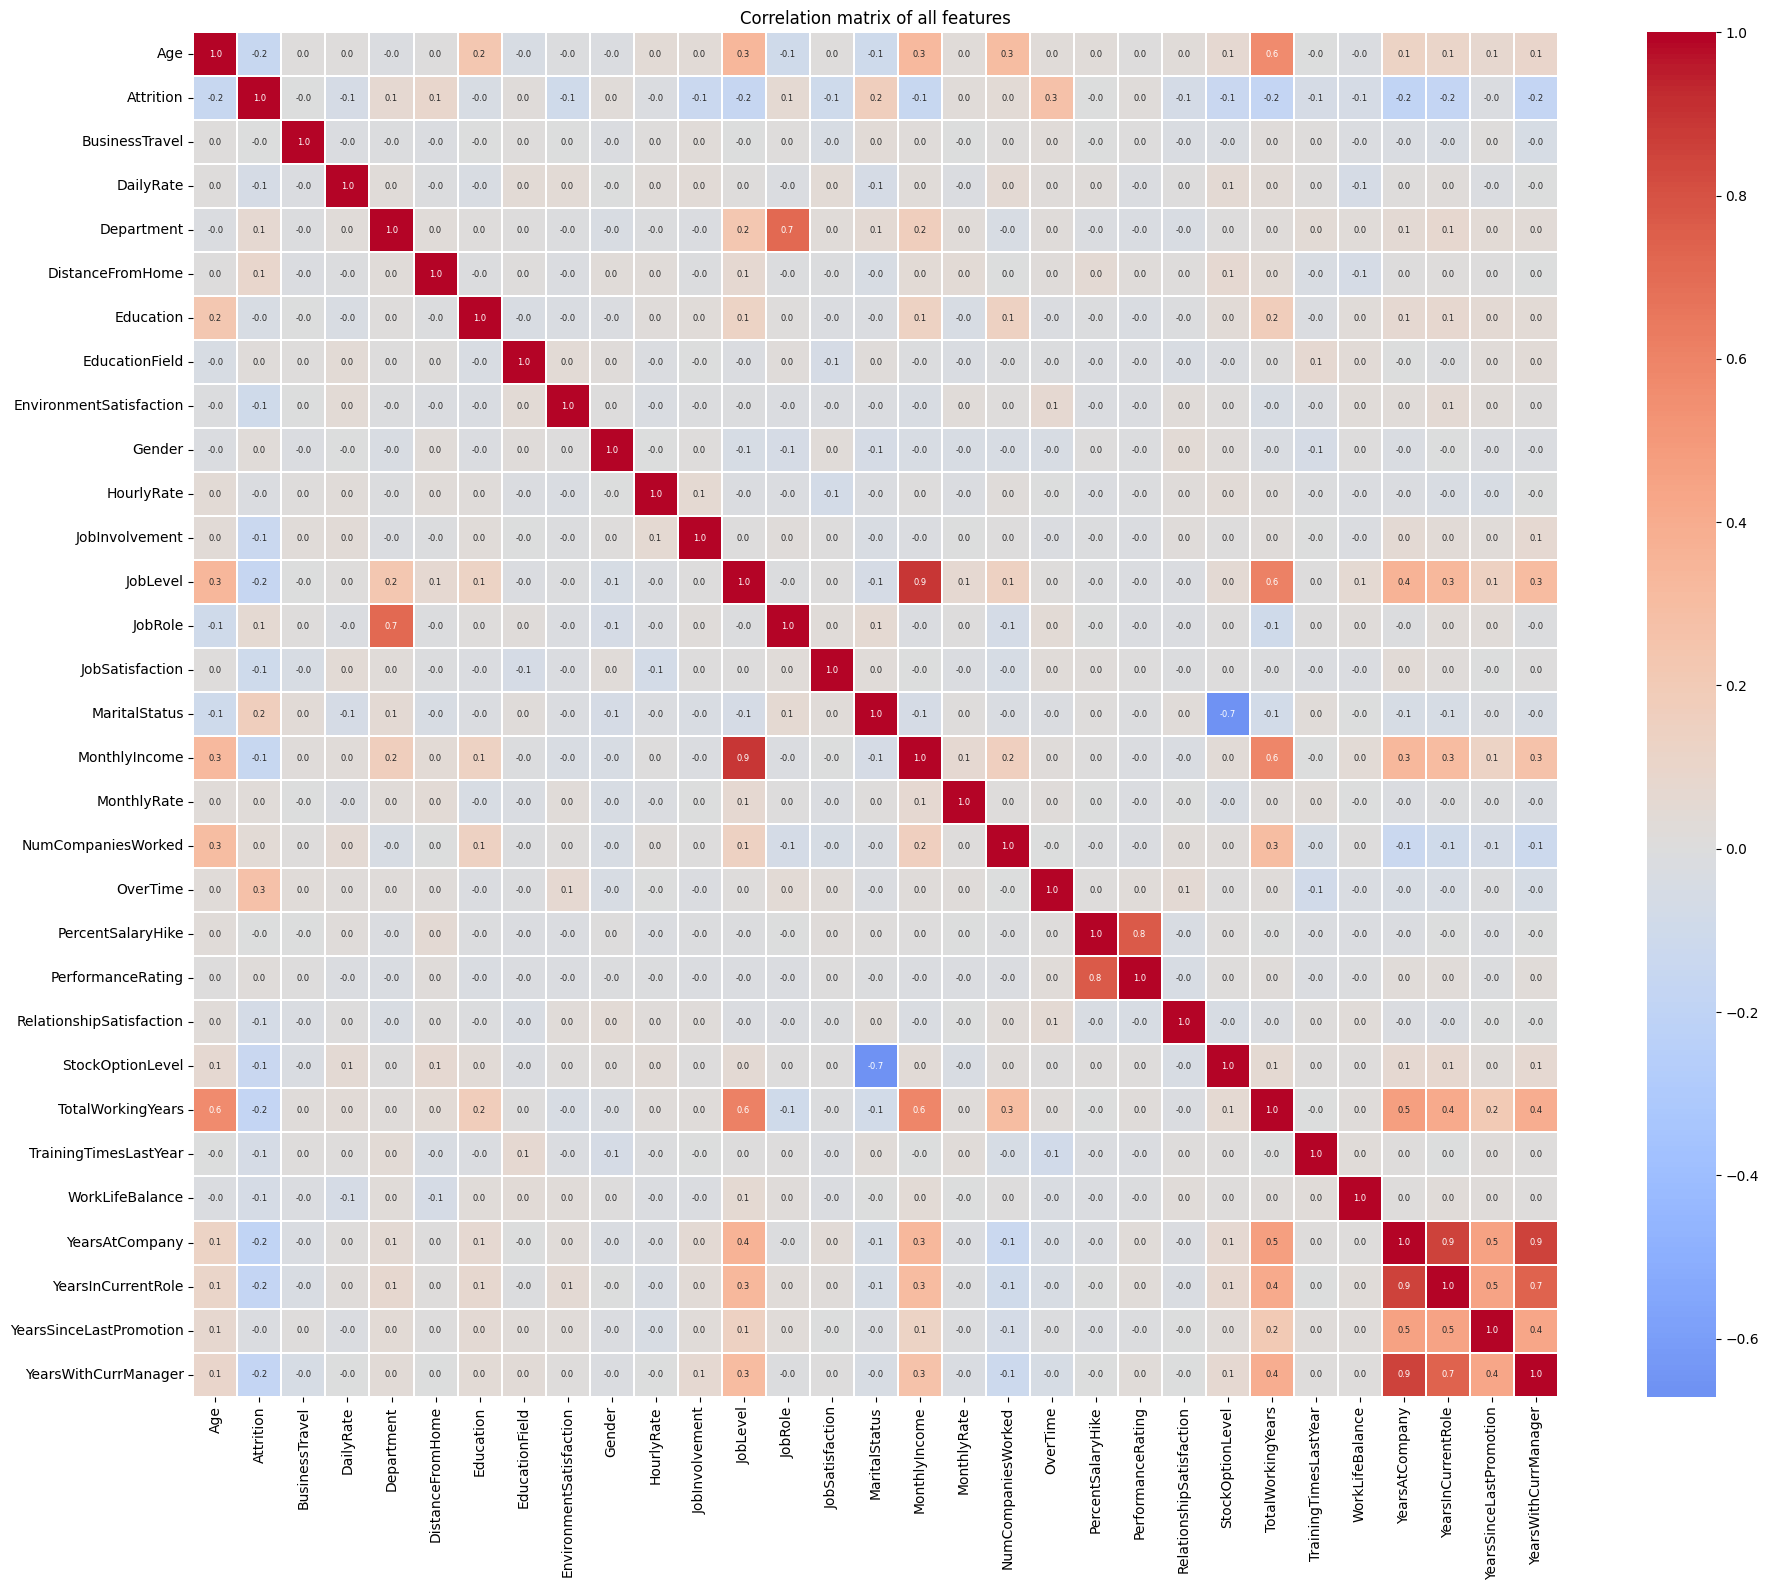

In [ ]:
corr = df.corr()

plt.figure(figsize=(20, 16))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 6}, linewidths=0.3, square=True)
plt.title("Correlation matrix of all features")
plt.tight_layout()
plt.show()

In [ ]:
corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10)

,Attrition
OverTime,0.268041
YearsAtCompany,-0.193681
TotalWorkingYears,-0.180377
YearsInCurrentRole,-0.178856
YearsWithCurrManager,-0.176153
MaritalStatus,0.165614
JobLevel,-0.158677
Age,-0.153349
MonthlyIncome,-0.149815
StockOptionLevel,-0.145253


## 7. Train / test split
Stratified so both sets keep the same share of employees who left.

In [ ]:
#X = df.filter( items=["OverTime","YearsAtCompany","TotalWorkingYears","YearsInCurrentRole","YearsWithCurrManager","MaritalStatus","JobLevel","Age","MonthlyIncome","StockOptionLevel"])
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(X_train.shape, X_test.shape)

(984, 30) (246, 30)


## 8. Train Logistic Regression and SVC
Both are scaled with `StandardScaler`. `class_weight='balanced'` handles the fact that few employees left.

In [ ]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    "SVC": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
}

results, preds = [], {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    preds[name] = pred
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, model.decision_function(X_test)),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.752,0.388,0.721,0.504,0.774
SVC,0.797,0.434,0.535,0.479,0.777


In [ ]:
for name, pred in preds.items():
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=["Stayed", "Left"], zero_division=0))

===== Logistic Regression =====
              precision    recall  f1-score   support

      Stayed       0.93      0.76      0.83       203
        Left       0.39      0.72      0.50        43

    accuracy                           0.75       246
   macro avg       0.66      0.74      0.67       246
weighted avg       0.83      0.75      0.78       246

===== SVC =====
              precision    recall  f1-score   support

      Stayed       0.90      0.85      0.87       203
        Left       0.43      0.53      0.48        43

    accuracy                           0.80       246
   macro avg       0.67      0.69      0.68       246
weighted avg       0.82      0.80      0.80       246



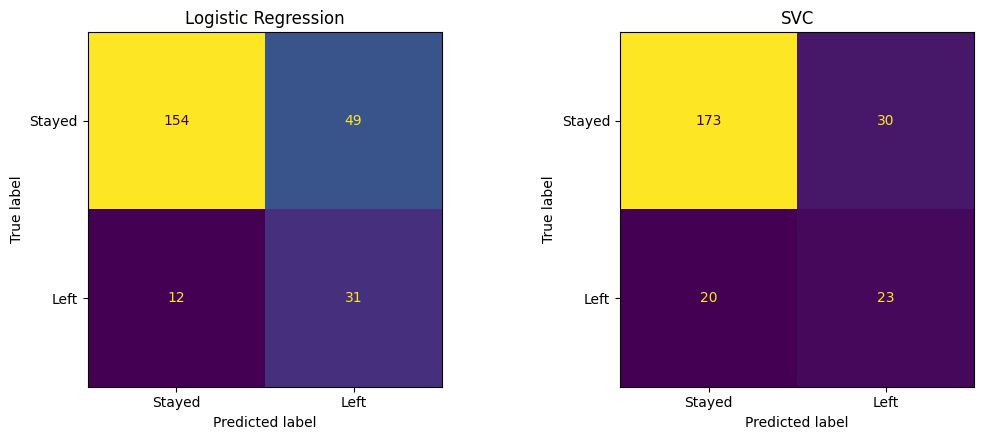

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Stayed", "Left"], ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()